# CampaignScore — Análise Exploratória de Dados (EDA)

> **Case de Machine Learning | Etapa 01 — Análise Exploratória**

## Contexto do case

O **CampaignScore** é um case de Machine Learning integrante do projeto **CRM Intelligence**, inspirado em um desafio de processo seletivo para Analista de Dados de CRM, proposto por uma empresa brasileira do segmento de delivery de alimentos.

O cenário do desafio representa uma empresa fictícia do varejo alimentício que busca melhorar a rentabilidade de suas campanhas de marketing direto. Uma campanha piloto, realizada com 2.240 clientes, apresentou taxa de conversão de aproximadamente 15%, gerando uma receita inferior ao custo da ação e um resultado financeiro negativo de 3.046 unidades monetárias (MU).

Esse resultado motivou a busca por uma abordagem orientada por dados, capaz de identificar clientes com maior propensão a aceitar ofertas e direcionar os esforços de marketing de maneira mais eficiente. **O objetivo central do case é desenvolver soluções analíticas que contribuam para maximizar a rentabilidade das campanhas.**

Os dados utilizados são públicos e representam o cenário fictício proposto no desafio, não correspondendo a registros reais de clientes da empresa que o inspirou.

## Objetivo desta etapa

Investigar a base preparada na etapa anterior, caracterizando o perfil dos clientes, seus padrões de consumo e relacionamento, e explorando associações entre essas características e a resposta à campanha piloto.

A etapa também contempla a construção de 13 variáveis derivadas que complementam as features originais/base e compõem o Feature Data utilizado nas análises e experimentos posteriores.

## Escopo e decisões da análise

- A análise parte da base curada no Notebook 00, preservando as decisões de preparação e tratamento realizadas anteriormente.
- A investigação contempla a distribuição de `Response`, o perfil sociodemográfico e familiar, os padrões de consumo e canais de compra, o histórico de campanhas, o engajamento digital e o relacionamento com a empresa.
- As 13 variáveis derivadas são construídas para ampliar as possibilidades de investigação e representação dos clientes.
- As comparações com `Response` possuem caráter descritivo e exploratório. Associações identificadas não demonstram causalidade nem comprovam contribuição preditiva individual.
- A seleção definitiva das features para segmentação e propensão pertence à etapa seguinte (Notebook 02 — Feature Analysis & Selection). Não há treinamento de modelos nesta etapa.

## Arquivos de saída

- **Feature Data em Parquet:** caminho definido por `FEATURES_DATA`, contendo a base preparada acrescida das 13 variáveis derivadas. O arquivo será utilizado pelas etapas posteriores de análise, seleção de features e experimentação dos modelos.

Os caminhos efetivos são centralizados no módulo `src.paths`.

## 1. Preparação do ambiente e visão geral dos dados

Esta seção configura o ambiente de análise, define funções auxiliares, carrega a base preparada e realiza uma inspeção inicial de estrutura, integridade e distribuição do target.

A distribuição de `Response` será apresentada logo no início porque estabelece a proporção de conversões observada na amostra e contextualiza as comparações realizadas nas seções seguintes.

In [1]:
# Importação das bibliotecas e configuração dos caminhos do projeto
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fonte local da base preparada
from src.paths import PROCESSED_DATA ,FEATURES_DATA

In [2]:
# Configuração de exibição e visualização
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=0.95
)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.linestyle": ":",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
    "axes.axisbelow": True,
})

COLOR_RESPONSE_0 = "#64748B"
COLOR_RESPONSE_1 = "#2878B5"

### 1.1 Funções auxiliares

Esta seção reúne três funções auxiliares utilizadas nas análises exploratórias para resumir e visualizar as taxas de resposta positiva por grupo.

- **`analyze_response`:** calcula, para cada grupo, a quantidade de clientes, o número de respostas positivas e a respectiva taxa de resposta. A taxa é obtida pela média da variável binária `Response`, apresentada em percentual. A função retorna uma tabela-resumo utilizada nas análises e visualizações subsequentes.
- **`plot_response_rate`:** constrói gráficos de barras horizontais para comparar as taxas de resposta entre categorias, incluindo a quantidade de clientes em cada grupo.
- **`plot_rate_points`:** representa as taxas de resposta por meio de gráficos de pontos, utilizando o tamanho dos marcadores para representar o volume de clientes. Permite investigar associações tanto entre categorias quanto ao longo de variáveis numéricas.

In [3]:
def analyze_response(df, group_col, target):
    """Resume volume e taxa de resposta positiva por grupo."""
    analysis = (
        df.groupby(group_col, observed=True)[target]
        .agg(
            Customers="size",
            PositiveResponses="sum",
            ResponseRate="mean"
        )
    )

    analysis["ResponseRate"] *= 100

    display(
        analysis.style.format({
            "Customers": "{:,.0f}",
            "PositiveResponses": "{:,.0f}",
            "ResponseRate": "{:.2f}%"
        })
    )

    return analysis

In [4]:
def plot_response_rate(ax, summary, title):
    """Plota taxas de resposta por categoria, com quantidade de clientes nas barras."""

    category_col = summary.index.name or "Grupo"
    plot_data = summary.reset_index()

    sns.barplot(
        data=plot_data,
        x="ResponseRate",
        y=category_col,
        ax=ax,
        color=COLOR_RESPONSE_1
    )

    # Anotações das taxas de resposta e quantidade de clientes
    for patch, (_, row) in zip(ax.patches, plot_data.iterrows()):
        ax.annotate(
            f"{row['ResponseRate']:.1f}%  |  n={int(row['Customers']):,}",
            (patch.get_width(), patch.get_y() + patch.get_height() / 2),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=8
        )

    max_rate = plot_data["ResponseRate"].max()

    ax.set_xlim(0, max_rate * 1.45 + 1)
    ax.set_title(title, loc="left", pad=10)
    ax.set_xlabel("Taxa de resposta positiva (%)")
    ax.set_ylabel("")
    sns.despine(ax=ax)

In [5]:
def plot_rate_points(
    ax,
    summary,
    title,
    xlabel,
    category_col=None,
    connect=False,
    show_customers=False,
    x_rotation=0
):
    """Plota taxas de resposta como pontos; o tamanho representa o número de clientes."""

    plot_data = summary.reset_index()
    category_col = category_col or summary.index.name or plot_data.columns[0]

    x_values = plot_data[category_col]
    y_values = plot_data["ResponseRate"]
    sizes = 45 + 220 * plot_data["Customers"] / plot_data["Customers"].max()

    # Posicionamento conforme a natureza da variável
    is_numeric = pd.api.types.is_numeric_dtype(x_values)

    x_plot = x_values if is_numeric else np.arange(len(plot_data))

    if connect:
        ax.plot(
            x_plot,
            y_values,
            color=COLOR_RESPONSE_0,
            linewidth=1.5,
            alpha=0.7,
            zorder=1
        )

    ax.scatter(
        x_plot,
        y_values,
        s=sizes,
        color=COLOR_RESPONSE_1,
        alpha=0.8,
        edgecolor="white",
        linewidth=0.8,
        zorder=2
    )

    for x, y, n in zip(x_plot, y_values, plot_data["Customers"]):
        label = f"{y:.1f}%"

        if show_customers:
            label += f"\n(n={int(n):,})"

        ax.annotate(
            label,
            (x, y),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

    ax.set_title(title, loc="left", pad=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Taxa de resposta positiva (%)")
    ax.set_xticks(x_plot)

    if not is_numeric:
        ax.set_xticklabels(x_values.astype(str))

    plt.setp(
        ax.get_xticklabels(),
        rotation=x_rotation,
        ha="right" if x_rotation else "center"
    )

    ax.set_ylim(0, y_values.max() * 1.25)

    ax.text(
        0.99, 0.98,
        "Tamanho do ponto proporcional ao número de clientes",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8,
        color="dimgray"
    )

    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)

### 1.2 Carregamento e visão inicial da base preparada

A base é carregada em formato Parquet a partir do caminho definido no projeto. Em seguida, o notebook apresenta uma amostra dos registros e as dimensões do conjunto para contextualizar as análises.

In [6]:
# Carregamento da base preparada
df = pd.read_parquet(PROCESSED_DATA)

TARGET = "Response"

display(df.head(3))
print(f"Formato inicial do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")

,ID,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,TenureDays
0,5524,Graduation,Single,"58,138.00",0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1,57,663
1,2174,Graduation,Single,"46,344.00",1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0,60,113
2,4141,Graduation,Partnered,"71,613.00",0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0,49,312


Formato inicial do dataset: 2229 linhas x 27 colunas


### 1.3 Qualidade e integridade dos dados

O relatório reúne tipos de dados, quantidade e percentual de valores ausentes e número de valores distintos. Também são verificadas duplicatas completas e duplicidade na chave `ID`.

A inspeção registrada anteriormente identificou 24 valores ausentes em `Income` (1,08%), sem duplicatas completas e sem IDs duplicados. Os valores ausentes em renda serão considerados nas análises que utilizam essa variável.

In [7]:
# Construção do relatório de qualidade e verificação de duplicidades
quality_report = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_ausentes": df.isna().sum(),
    "percentual_ausente": (df.isna().mean() * 100),
    "valores_distintos": df.nunique(dropna=False),
}).sort_values(
    ["valores_ausentes", "valores_distintos"],
    ascending=[False, False]
)

print(f"Duplicatas completas: {df.duplicated().sum():,}")
if "ID" in df.columns:
    print(f"IDs duplicados: {df['ID'].duplicated().sum():,}")

display(quality_report)

Duplicatas completas: 0
IDs duplicados: 0


,tipo,valores_ausentes,percentual_ausente,valores_distintos
Income,float64,24,1.08,1964
ID,int64,0,0.00,2229
MntWines,int32,0,0.00,775
TenureDays,int16,0,0.00,663
MntMeatProducts,int32,0,0.00,555
MntGoldProds,int32,0,0.00,213
MntFishProducts,int32,0,0.00,182
MntSweetProducts,int32,0,0.00,177
MntFruits,int32,0,0.00,158
Recency,int16,0,0.00,100


### 1.4 Distribuição da variável target

A variável `Response` é binária e representa a compra da oferta apresentada na campanha piloto. A tabela e o gráfico apresentam quantidade e participação de cada classe.

Na base preparada, foram observados 1.895 clientes sem resposta positiva e 334 clientes com resposta positiva, correspondendo a uma taxa geral de 14,98%. A proporção evidencia a predominância da classe negativa e deverá ser considerada posteriormente na avaliação dos modelos.

In [8]:
# Distribuição do target
target_summary = pd.DataFrame({
    "quantidade": df[TARGET].value_counts(dropna=False),
    "proporcao": df[TARGET].value_counts(normalize=True, dropna=False),
}).sort_index()

display(target_summary.style.format({"proporcao": "{:.2%}"}))

,quantidade,proporcao
Response,,
0,1895,85.02%
1,334,14.98%


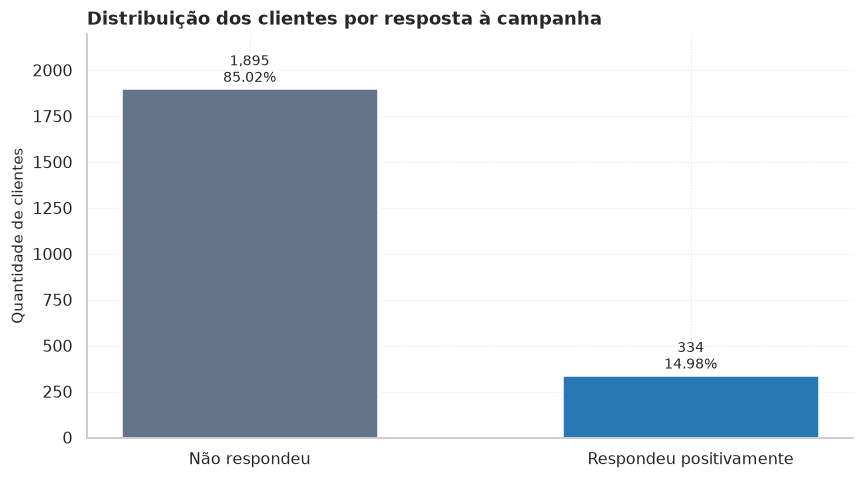

In [9]:
# Visualização 1 — Distribuição da variável Response
target_plot = (
    df[TARGET]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Não respondeu",
        1: "Respondeu positivamente"
    })
    .rename_axis("Resultado")
    .reset_index(name="Customers")
)
target_plot["Share"] = target_plot["Customers"] / len(df) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(
    target_plot["Resultado"],
    target_plot["Customers"],
    color=[COLOR_RESPONSE_0, COLOR_RESPONSE_1],
    width=0.58
)

for bar, (_, row) in zip(bars, target_plot.iterrows()):
    ax.annotate(
        f"{int(row['Customers']):,}\n{row['Share']:.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title("Distribuição dos clientes por resposta à campanha", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Quantidade de clientes")
ax.set_ylim(0, target_plot["Customers"].max() * 1.16)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**Síntese da seção**

A base preparada contém 2.229 clientes, sem duplicatas completas ou IDs duplicados. `Income` é a única variável com ausência registrada: 24 observações (1,08%). A resposta positiva corresponde a 334 clientes (14,98%), enquanto 1.895 clientes (85,02%) não compraram a oferta.

Esses resultados estabelecem a população e a distribuição do target que serão utilizadas como referência nas análises seguintes.

## 2. Feature Engineering

Esta seção constrói as 13 variáveis derivadas que complementam as features originais/base e integram o Feature Data.

Os valores ausentes de `Income` são preservados, deixando seu tratamento para as etapas posteriores de preparação dos dados.

`IncomeGroup` e `TenureGroup` são agrupamentos construídos para apoiar as análises descritivas. Embora integrem o Feature Data exportado, não serão utilizadas como atributos nos experimentos de segmentação nem no modelo preditivo.

In [10]:
# Composição familiar

df["ChildrenAtHome"] = df["Kidhome"] + df["Teenhome"]
df["HasChildren"] = (df["ChildrenAtHome"] > 0).astype("int8")
df["FamilyProfile"] = (
    df["Marital_Status"].astype("string")
    + " | "
    + df["HasChildren"].map({0: "Without Children", 1: "With Children"}).astype("string")
).astype("category")

In [11]:
# Faixas socioeconômica e demográfica

df["IncomeGroup"] = pd.qcut(
    df["Income"], q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)
df["AgeGroup"] = pd.cut(
    df["Age"], bins=[17, 30, 45, 60, float("inf")],
    labels=["18-30", "31-45", "46-60", "61+"], ordered=True
)

In [12]:
# Consumo agregado
spend_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]
df["TotalSpend"] = df[spend_cols].sum(axis=1).astype("int32")

In [13]:
# Representação de canais de compra
channel_cols = ["NumWebPurchases", "NumStorePurchases", "NumCatalogPurchases"]
channel_names = ["Web", "Store", "Catalog"]
channel_frequency = df[channel_cols].copy()
channel_frequency.columns = channel_names

if channel_frequency.isna().any().any() or (channel_frequency < 0).any().any():
    raise ValueError("Os canais de compra contêm valores ausentes ou negativos.")
    
active_channels = channel_frequency.gt(0).sum(axis=1)
max_purchases = channel_frequency.max(axis=1)
channels_at_max = channel_frequency.eq(max_purchases, axis=0).sum(axis=1)
preferred_channel = pd.Series(index=df.index, dtype="object")
preferred_channel.loc[active_channels.eq(0)] = "No Purchases"
preferred_channel.loc[active_channels.gt(0) & channels_at_max.gt(1)] = "Tied Channels"
single_preference = active_channels.gt(0) & channels_at_max.eq(1)
preferred_channel.loc[single_preference] = channel_frequency.loc[single_preference].idxmax(axis=1)

df["PreferredChannel"] = preferred_channel.astype("category")
df["NumActiveChannels"] = active_channels.astype("int8")

In [14]:
# Histórico agregado de campanhas
campaign_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]
df["PreviousCampaignsAccepted"] = df[campaign_cols].sum(axis=1).astype("int8")

In [15]:
# Engajamento digital agrupado
df["WebVisitsGroup"] = pd.cut(
    df["NumWebVisitsMonth"], bins=[-1, 2, 5, 8, float("inf")],
    labels=["0–2 visits", "3–5 visits", "6–8 visits", "9+ visits"], ordered=True
)

In [16]:
# Relacionamento e recência
df["TenureGroup"] = pd.qcut(
    df["TenureDays"], q=4,
    labels=["New", "Short", "Long", "Very Long"]
)
df["RecencyGroup"] = pd.cut(
    df["Recency"], bins=[-1, 30, 60, 90, float("inf")],
    labels=["Up to 30 days", "31-60 days", "61-90 days", "Over 90 days"], ordered=True
)

In [17]:
# Volume total de compras nos três canais
df["TotalPurchases"] = df[channel_cols].sum(axis=1)

In [18]:
# Registro e conferência das 13 variáveis derivadas do Feature Engineering
DERIVED_FEATURES = [
    "ChildrenAtHome", "HasChildren", "FamilyProfile", "IncomeGroup", "AgeGroup",
    "TotalSpend", "PreferredChannel", "NumActiveChannels", "PreviousCampaignsAccepted",
    "WebVisitsGroup", "TenureGroup", "RecencyGroup", "TotalPurchases"
]
assert len(DERIVED_FEATURES) == 13
assert not df[DERIVED_FEATURES].columns.duplicated().any()
print(f"Variáveis derivadas construídas: {len(DERIVED_FEATURES)}")
display(df[DERIVED_FEATURES].head(3))

Variáveis derivadas construídas: 13


,ChildrenAtHome,HasChildren,FamilyProfile,IncomeGroup,AgeGroup,TotalSpend,PreferredChannel,NumActiveChannels,PreviousCampaignsAccepted,WebVisitsGroup,TenureGroup,RecencyGroup,TotalPurchases
0,0,0,Single | Without Children,Medium-High,46-60,1617,Catalog,3,0,6–8 visits,Very Long,31-60 days,22
1,2,1,Single | With Children,Medium-Low,46-60,27,Store,3,0,3–5 visits,New,31-60 days,4
2,0,0,Partnered | Without Children,High,46-60,776,Store,3,0,3–5 visits,Short,Up to 30 days,20


## 3. Perfil demográfico, socioeconômico e familiar

Esta seção investiga características demográficas, socioeconômicas e familiares dos clientes e verifica como essas características se relacionam com `Response`.

O objetivo é identificar diferenças entre grupos sem interpretar associações descritivas como relações causais. As quantidades de clientes serão consideradas junto às taxas de resposta, principalmente nas categorias menores.

### 3.1 Estado civil e composição familiar

Esta seção investiga a composição familiar dos clientes, considerando o estado civil e a presença de filhos no domicílio.

São utilizadas as variáveis `ChildrenAtHome`, `HasChildren` e `FamilyProfile` para caracterizar os grupos familiares e explorar diferenças de renda entre os perfis identificados.

Na tabela de renda por perfil familiar, `Customers` representa o total de clientes do grupo, enquanto `IncomeObservations` indica quantos possuem renda informada e participam do cálculo da média.

In [19]:
# Estado civil × presença de filhos
family_counts = pd.crosstab(
    df["Marital_Status"],
    df["HasChildren"]
)

family_counts.columns = [
    "Without Children",
    "With Children"
]

display(family_counts)

,Without Children,With Children
Marital_Status,,
Divorced,57,173
Partnered,380,1056
Single,169,317
Widow,27,50


In [20]:
# Perfil familiar × renda média, distinguindo o total de clientes das rendas disponíveis
income_by_family = (
    df.groupby("FamilyProfile", observed=True)
    .agg(
        Customers=("ID", "size"),
        IncomeObservations=("Income", "count"),
        MeanIncome=("Income", "mean")
    )
    .sort_values("MeanIncome", ascending=False)
)

display(income_by_family)

,Customers,IncomeObservations,MeanIncome
FamilyProfile,,,
Single | Without Children,169,168,"66,035.42"
Partnered | Without Children,380,377,"65,035.92"
Widow | Without Children,27,26,"63,978.38"
Divorced | Without Children,57,57,"63,216.93"
Widow | With Children,50,50,"52,583.20"
Divorced | With Children,173,173,"48,922.61"
Partnered | With Children,1056,1045,"46,523.46"
Single | With Children,317,309,"42,840.26"


### 3.2 Perfil socioeconômico

A escolaridade é comparada à renda média para descrever diferenças socioeconômicas entre os grupos. Em seguida, `Income` é discretizada em quatro faixas por quartis (`IncomeGroup`) e a taxa de resposta é calculada para cada faixa.

Como os intervalos são definidos por quantis, os grupos tendem a apresentar tamanhos semelhantes. Os 24 registros sem renda permanecem sem classificação em `IncomeGroup` e não participam dessa comparação.

Na tabela por escolaridade, `Customers` representa o total de clientes de cada grupo e `IncomeObservations` contabiliza apenas as rendas não ausentes utilizadas no cálculo da média.

In [21]:
# Análise da taxa de resposta por faixa de renda
income_response = analyze_response(df, "IncomeGroup", TARGET)

,Customers,PositiveResponses,ResponseRate
IncomeGroup,,,
Low,553,58,10.49%
Medium-Low,550,69,12.55%
Medium-High,551,57,10.34%
High,551,149,27.04%


In [22]:
# Escolaridade × renda média, distinguindo o total de clientes das rendas disponíveis
income_by_education = (
    df.groupby("Education", observed=True)
    .agg(
        Customers=("ID", "size"),
        IncomeObservations=("Income", "count"),
        MeanIncome=("Income", "mean")
    )
    .sort_values("MeanIncome", ascending=False)
)

display(income_by_education)

,Customers,IncomeObservations,MeanIncome
Education,,,
PhD,481,476,"55,220.58"
Master,369,364,"52,629.58"
Graduation,1124,1113,"51,984.01"
2n Cycle,201,198,"47,625.33"
Basic,54,54,"20,306.26"


A faixa `High` apresenta taxa de resposta de 27,04%, enquanto as outras três faixas apresentam taxas entre 10,34% e 12,55%. A diferença indica associação entre renda e resposta à campanha na amostra analisada. Não permite concluir que renda, isoladamente, determine a conversão.

### 3.3 Faixa etária

A variável `AgeGroup` segmenta os clientes em quatro faixas etárias definidas previamente. A análise compara a taxa de resposta entre esses grupos, preservando a idade contínua (`Age`) na base para outras investigações.

In [23]:
# Faixa etária × Response
age_response = analyze_response(df, "AgeGroup", TARGET)

,Customers,PositiveResponses,ResponseRate
AgeGroup,,,
18-30,259,47,18.15%
31-45,969,149,15.38%
46-60,736,95,12.91%
61+,265,43,16.23%


### 3.4 Escolaridade e perfil familiar × Response

As comparações abaixo verificam se as taxas de resposta variam conforme escolaridade e perfil familiar. A função auxiliar apresenta, para cada grupo, o total de clientes, as respostas positivas e a taxa correspondente.

In [24]:
# Escolaridade × Response
education_response = analyze_response(df, "Education", TARGET)

,Customers,PositiveResponses,ResponseRate
Education,,,
2n Cycle,201,22,10.95%
Basic,54,2,3.70%
Graduation,"1,124",152,13.52%
Master,369,57,15.45%
PhD,481,101,21.00%


In [25]:
# Perfil familiar × Response
family_response = analyze_response(df, "FamilyProfile", TARGET)

,Customers,PositiveResponses,ResponseRate
FamilyProfile,,,
Divorced | With Children,173,22,12.72%
Divorced | Without Children,57,26,45.61%
Partnered | With Children,"1,056",91,8.62%
Partnered | Without Children,380,67,17.63%
Single | With Children,317,43,13.56%
Single | Without Children,169,66,39.05%
Widow | With Children,50,9,18.00%
Widow | Without Children,27,10,37.04%


### 3.5 Visualização comparativa das taxas de resposta

Os quatro painéis comparam as taxas de resposta de escolaridade, perfil familiar, renda e idade. Os rótulos apresentam a taxa e o tamanho da amostra de cada grupo, evitando que percentuais de grupos pequenos sejam interpretados sem contexto.

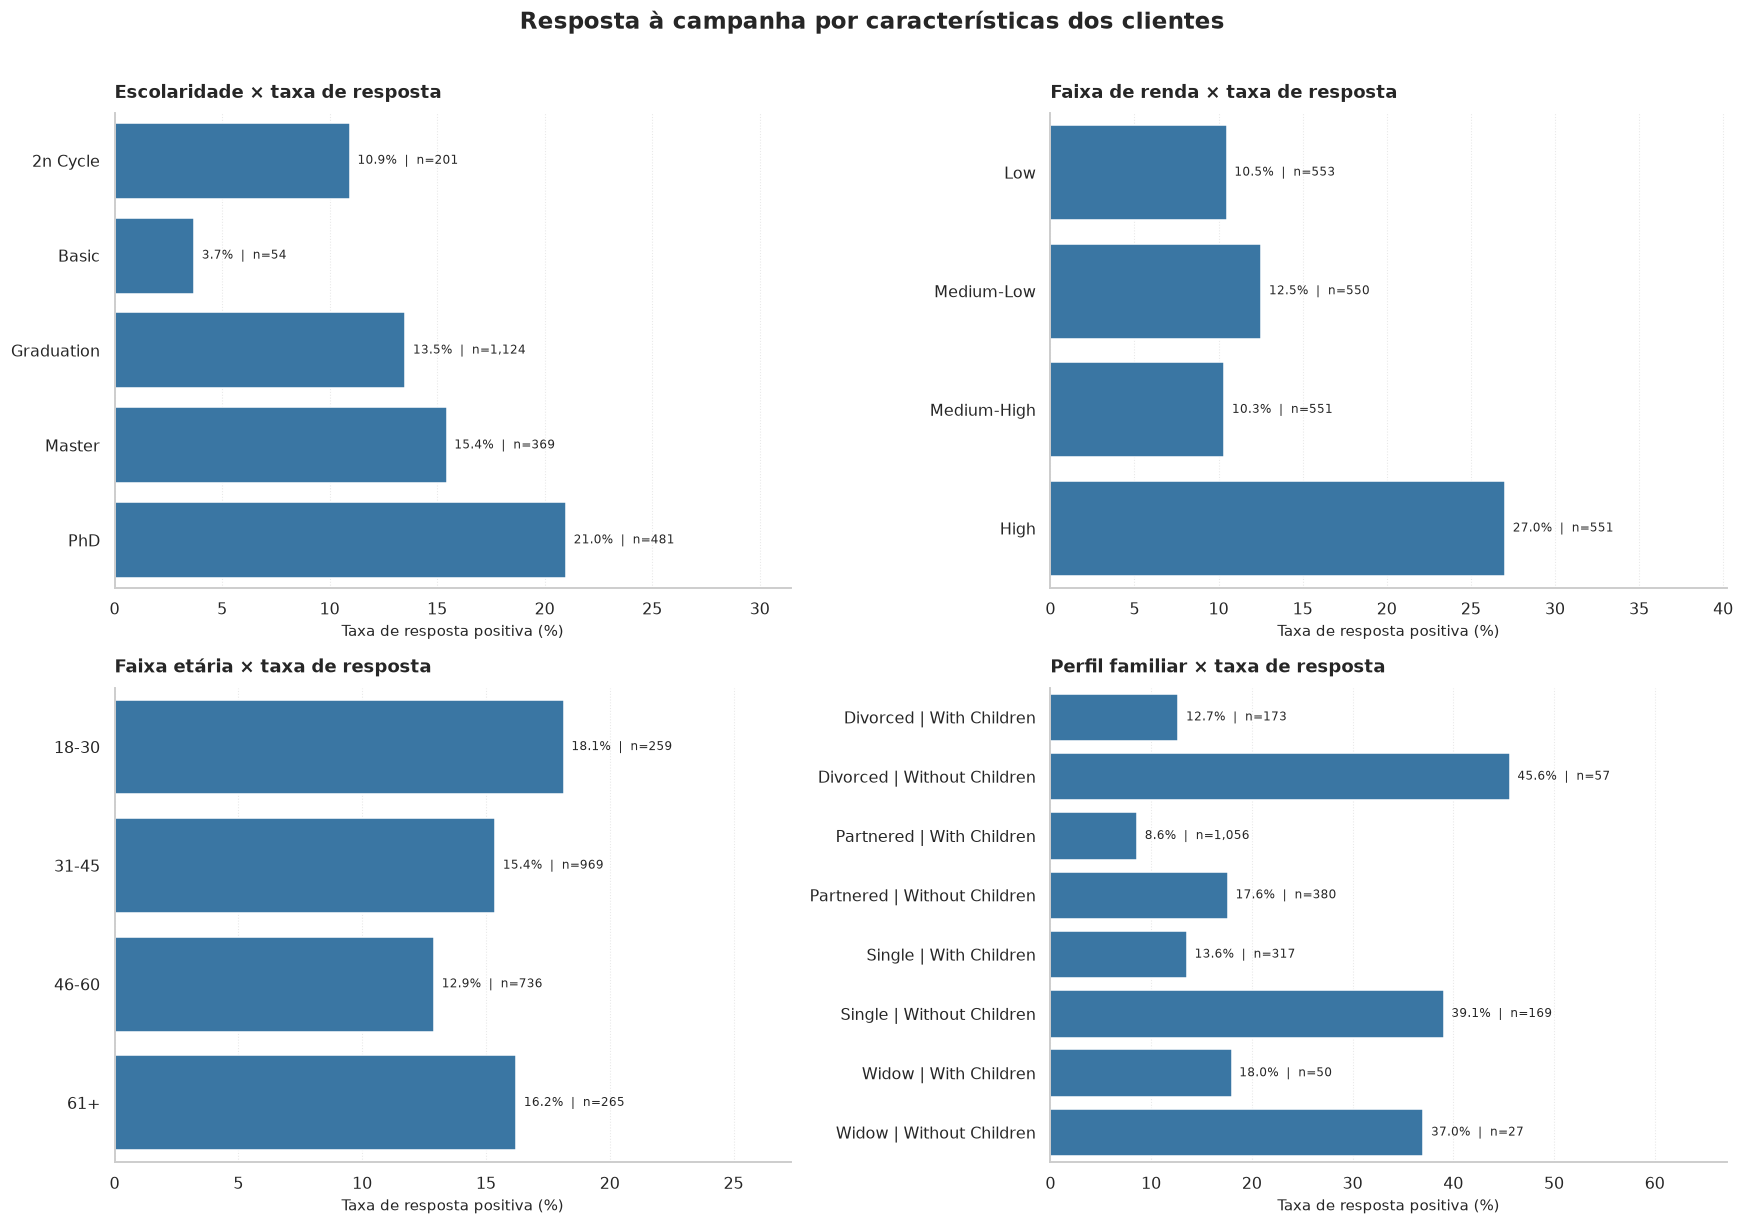

In [26]:
# Visualização 2 — Perfil sociodemográfico e familiar × Response
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

plot_response_rate(axes[0, 0], education_response, "Escolaridade × taxa de resposta")
plot_response_rate(axes[0, 1], income_response, "Faixa de renda × taxa de resposta")
plot_response_rate(axes[1, 0], age_response, "Faixa etária × taxa de resposta")
plot_response_rate(axes[1, 1], family_response, "Perfil familiar × taxa de resposta")

fig.suptitle("Resposta à campanha por características dos clientes", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

**Síntese da seção**

As diferenças mais expressivas aparecem entre as faixas de renda e os perfis familiares. A faixa de renda `High` apresenta 27,04% de resposta; entre os perfis familiares, `Divorced | Without Children` registra 45,61% (57 clientes) e `Single | Without Children`, 39,05% (169 clientes). Esses grupos menores exigem cautela na interpretação.

Na escolaridade, a taxa varia de 3,70% em `Basic` (54 clientes) a 21,00% em `PhD` (481 clientes). Entre as faixas etárias, a variação não apresenta progressão linear: o grupo de 18–30 anos registra 18,15%, enquanto o grupo de 46–60 anos registra 12,91%.

As características sociodemográficas descrevem diferenças entre os grupos, mas deverão ser avaliadas em conjunto com as demais dimensões antes de qualquer conclusão sobre seu valor preditivo.

## 4. Consumo e comportamento de compras

Esta seção investiga o volume e a composição dos gastos, a utilização de descontos e a frequência de compras nos diferentes canais. Também compara o comportamento de consumo entre clientes que responderam e não responderam positivamente à campanha.

Os valores das variáveis `Mnt*` representam gastos acumulados nos últimos dois anos, expressos em MU. As variáveis de frequência representam contagens de compras registradas por canal.

### 4.1 Composição do gasto total

`TotalSpend` é derivada pela soma dos gastos nas seis categorias de produtos. A variável agrega o volume de consumo por cliente e é utilizada nas comparações seguintes. As tabelas apresentam o gasto total e a composição por categoria segundo as faixas de renda e o perfil familiar.

In [27]:
# Faixa de renda × gastos
income_spend = (
    df.dropna(subset=["IncomeGroup"])
    .groupby("IncomeGroup", observed=True)
    .agg(
        Customers=("ID", "size"),
        MeanTotalSpend=("TotalSpend", "mean"),
        MeanWines=("MntWines", "mean"),
        MeanFruits=("MntFruits", "mean"),
        MeanMeat=("MntMeatProducts", "mean"),
        MeanFish=("MntFishProducts", "mean"),
        MeanSweets=("MntSweetProducts", "mean"),
        MeanGold=("MntGoldProds", "mean")
    )
)

display(income_spend)

,Customers,MeanTotalSpend,MeanWines,MeanFruits,MeanMeat,MeanFish,MeanSweets,MeanGold
IncomeGroup,,,,,,,,
Low,553,81.63,21.52,5.95,22.69,8.68,5.93,16.86
Medium-Low,550,229.78,124.41,8.00,48.05,13.53,8.47,27.32
Medium-High,551,750.70,435.24,30.43,158.30,39.31,28.21,59.21
High,551,"1,366.40",644.19,61.28,432.51,89.57,65.95,72.91


In [28]:
# Perfil familiar × gastos
family_spend = (
    df.groupby("FamilyProfile", observed=True)
    .agg(
        Customers=("ID", "size"),
        MeanTotalSpend=("TotalSpend", "mean"),
        MeanWines=("MntWines", "mean"),
        MeanFruits=("MntFruits", "mean"),
        MeanMeat=("MntMeatProducts", "mean"),
        MeanFish=("MntFishProducts", "mean"),
        MeanSweets=("MntSweetProducts", "mean"),
        MeanGold=("MntGoldProds", "mean")
    )
    .sort_index()
)

display(family_spend)

,Customers,MeanTotalSpend,MeanWines,MeanFruits,MeanMeat,MeanFish,MeanSweets,MeanGold
FamilyProfile,,,,,,,,
Divorced | With Children,173,480.03,286.22,19.10,93.08,22.21,18.53,40.89
Divorced | Without Children,57,"1,027.19",453.19,53.54,328.70,75.09,52.82,63.84
Partnered | With Children,1056,413.45,236.79,15.94,86.26,22.00,17.06,35.40
Partnered | Without Children,380,"1,104.12",488.67,52.44,367.64,78.46,52.98,63.94
Single | With Children,317,328.00,172.94,13.82,72.53,20.72,13.45,34.56
Single | Without Children,169,"1,130.86",505.79,51.41,385.92,72.26,52.73,62.76
Widow | With Children,50,515.78,307.02,19.44,88.44,31.06,25.48,44.34
Widow | Without Children,27,"1,151.85",484.56,58.37,376.04,89.04,64.07,79.78


A tabela por faixa de renda mostra uma diferença acentuada no gasto médio: 81,63 MU em `Low`, 229,78 MU em `Medium-Low`, 750,70 MU em `Medium-High` e 1.366,40 MU em `High`. O padrão indica associação entre renda e volume de consumo.

Nos perfis familiares, os grupos sem filhos apresentam gastos médios superiores aos respectivos grupos com filhos. Essa comparação é descritiva e não isola o efeito da composição familiar de outras características, como a renda.

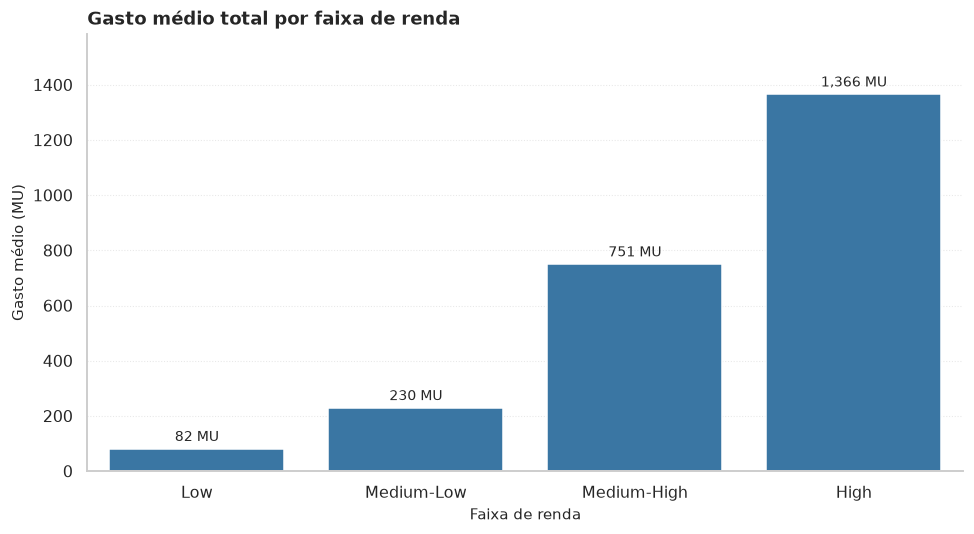

In [29]:
# Visualização 3 — Faixa de renda × gasto médio total
income_spend_plot = income_spend.reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=income_spend_plot,
    x="IncomeGroup",
    y="MeanTotalSpend",
    ax=ax,
    color=COLOR_RESPONSE_1
)

for patch, value in zip(ax.patches, income_spend_plot["MeanTotalSpend"]):
    ax.annotate(
        f"{value:,.0f} MU",
        (patch.get_x() + patch.get_width() / 2, patch.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title("Gasto médio total por faixa de renda", loc="left")
ax.set_xlabel("Faixa de renda")
ax.set_ylabel("Gasto médio (MU)")
ax.set_ylim(0, income_spend_plot["MeanTotalSpend"].max() * 1.16)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 4.2 Compras com desconto × Response

`NumDealsPurchases` representa a quantidade de compras realizadas com desconto. A análise compara a taxa de resposta positiva para cada quantidade observada.

A distribuição deve ser interpretada considerando o tamanho dos grupos: categorias de frequência elevada possuem poucos clientes e, portanto, suas taxas podem oscilar bastante. O gráfico utiliza o tamanho dos pontos para representar o volume de clientes em cada categoria.

In [30]:
# Compras com desconto × Response
deals_response = analyze_response(df, "NumDealsPurchases", TARGET)

,Customers,PositiveResponses,ResponseRate
NumDealsPurchases,,,
0,41,16,39.02%
1,967,160,16.55%
2,497,48,9.66%
3,297,38,12.79%
4,188,26,13.83%
5,94,16,17.02%
6,61,12,19.67%
7,40,8,20.00%
8,14,1,7.14%


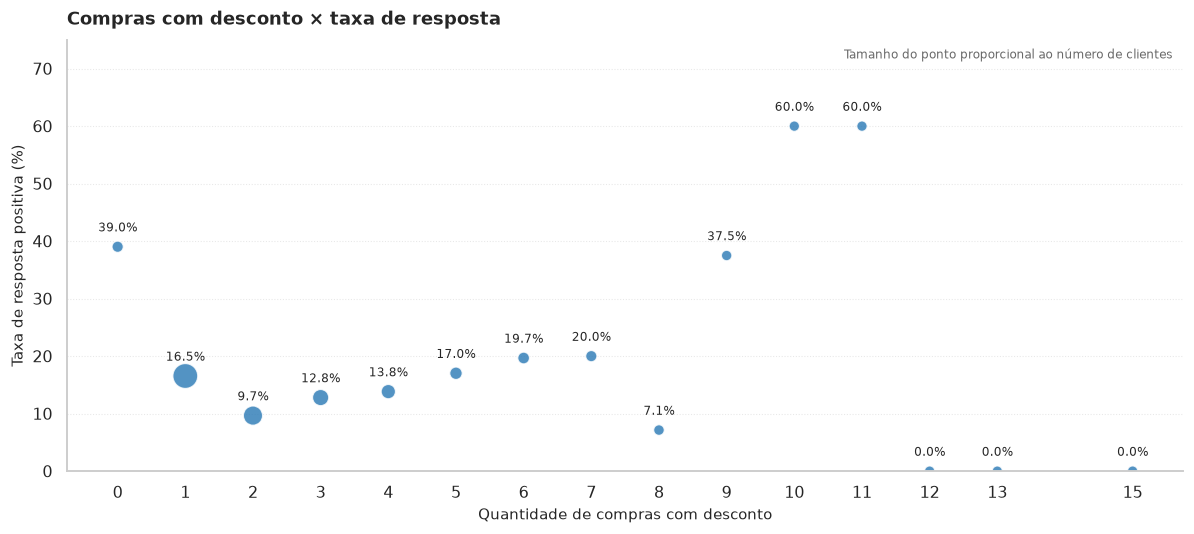

In [31]:
# Visualização 4 — Compras com desconto × taxa de resposta

_deals_plot = deals_response.sort_index()

fig, ax = plt.subplots(figsize=(11, 5))

plot_rate_points(
    ax,
    _deals_plot,
    title="Compras com desconto × taxa de resposta",
    xlabel="Quantidade de compras com desconto"
)

plt.tight_layout()
plt.show()

A taxa de resposta não apresenta uma relação monotônica com a quantidade de compras com desconto. O grupo com zero compras registra 39,02%, mas contém apenas 41 clientes. Entre os grupos mais numerosos, a taxa varia de 9,66% para duas compras a 20,00% para sete compras.

As categorias com frequências elevadas possuem amostras pequenas. Por exemplo, os grupos de 10 e 11 compras contêm cinco clientes cada. Seus percentuais não devem ser interpretados como padrões estáveis.

### 4.3 Categorias de produtos × Response

A comparação avalia se os clientes que responderam positivamente apresentam padrões de gastos diferentes entre as seis categorias de produtos. Para cada categoria, são calculadas média e mediana por classe de `Response`.

A média resume o nível geral de gasto e pode ser influenciada por valores elevados; a mediana fornece uma medida adicional da posição central da distribuição.

In [32]:
# Categorias de produtos × Response
product_response = (
    df.groupby(TARGET)[spend_cols]
    .agg(["mean", "median"])
    .T
    .rename(columns={
        0: "Não respondeu",
        1: "Respondeu positivamente"
    })
)

product_response.index.names = ["ProductCategory", "Statistic"]

display(product_response)

Response                    Não respondeu  Respondeu positivamente
ProductCategory  Statistic                                        
MntWines         mean              270.14                   502.70
                 median            154.00                   448.00
MntFruits        mean               24.26                    38.20
                 median              7.00                    21.00
MntMeatProducts  mean              142.54                   294.35
                 median             56.00                   174.50
MntFishProducts  mean               35.10                    52.05
                 median             11.00                    25.00
MntSweetProducts mean               25.14                    38.63
                 median              7.00                    20.00
MntGoldProds     mean               41.06                    61.45
                 median             21.00                    39.50

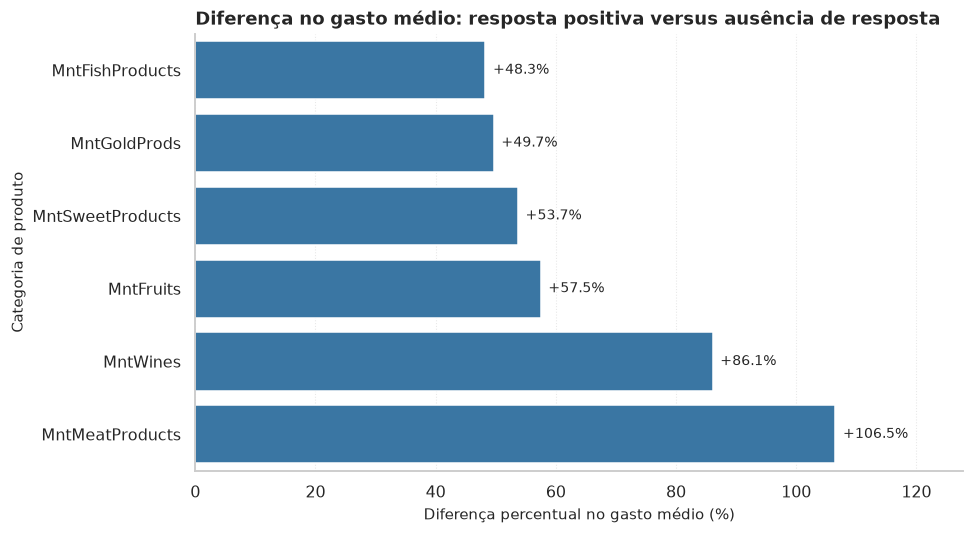

In [33]:
# Visualização 5 — Diferença percentual do gasto médio por categoria
_product_means = (
    df.groupby(TARGET)[spend_cols]
    .mean()
    .T
    .rename(columns={
        0: "Não respondeu",
        1: "Respondeu positivamente"
    })
)

product_uplift = (
    (
        _product_means["Respondeu positivamente"]
        / _product_means["Não respondeu"]
        - 1
    ) * 100
).sort_values()

_product_uplift_plot = product_uplift.rename("DifferencePct").reset_index()
_product_uplift_plot = _product_uplift_plot.rename(columns={"index": "ProductCategory"})

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=_product_uplift_plot,
    x="DifferencePct",
    y="ProductCategory",
    ax=ax,
    color=COLOR_RESPONSE_1
)

for patch, value in zip(ax.patches, _product_uplift_plot["DifferencePct"]):
    ax.annotate(
        f"+{value:.1f}%",
        (patch.get_width(), patch.get_y() + patch.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set_title("Diferença no gasto médio: resposta positiva versus ausência de resposta", loc="left")
ax.set_xlabel("Diferença percentual no gasto médio (%)")
ax.set_ylabel("Categoria de produto")
ax.set_xlim(0, _product_uplift_plot["DifferencePct"].max() * 1.2)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

Em todas as seis categorias, os clientes que responderam positivamente apresentam gastos médios e medianos superiores. A maior diferença percentual na média aparece em `MntMeatProducts` (+106,5%), enquanto `MntWines` apresenta a maior diferença absoluta entre as médias (232,56 MU).

O padrão também aparece nas medianas, indicando que a diferença não está restrita apenas aos maiores valores individuais. Ainda assim, essas comparações não isolam o efeito de renda, perfil familiar ou histórico de campanhas.

### 4.4 Frequência e utilização dos canais de compra

As variáveis `NumWebPurchases`, `NumStorePurchases` e `NumCatalogPurchases` representam a frequência de compras nos três canais. Primeiro, são comparadas média, mediana e desvio-padrão; depois, a correlação de Spearman investiga se a frequência de compra nos canais tende a variar conjuntamente.

In [34]:
# Resumo estatístico da frequência de compras por canal
channel_cols = {
    "Web": "NumWebPurchases",
    "Store": "NumStorePurchases",
    "Catalog": "NumCatalogPurchases"
}

channel_summary = (
    df[list(channel_cols.values())]
    .agg(["count", "mean", "median", "std"])
    .T
    .rename(columns={
        "count": "Customers",
        "mean": "MeanPurchases",
        "median": "MedianPurchases",
        "std": "StdPurchases"
    })
    .rename_axis("Channel")
    .rename(index={
        "NumWebPurchases": "Web",
        "NumStorePurchases": "Store",
        "NumCatalogPurchases": "Catalog"
    })
)

display(channel_summary)

,Customers,MeanPurchases,MedianPurchases,StdPurchases
Channel,,,,
Web,"2,229.00",4.10,4.00,2.78
Store,"2,229.00",5.81,5.00,3.24
Catalog,"2,229.00",2.64,2.00,2.80


In [35]:
# Correlação de Spearman entre canais
channel_corr = (
    df[list(channel_cols.values())]
    .corr(method="spearman")
    .rename(index={
        "NumWebPurchases": "Web",
        "NumStorePurchases": "Store",
        "NumCatalogPurchases": "Catalog"
    })
    .rename(columns={
        "NumWebPurchases": "Web",
        "NumStorePurchases": "Store",
        "NumCatalogPurchases": "Catalog"
    })
)

display(channel_corr)

,Web,Store,Catalog
Web,1.00,0.67,0.62
Store,0.67,1.00,0.71
Catalog,0.62,0.71,1.00


A loja física apresenta a maior média de compras (5,81), seguida por Web (4,10) e Catálogo (2,64). As correlações de Spearman entre os canais variam de 0,62 a 0,71, indicando associações positivas entre as frequências de compra. Portanto, os canais não devem ser tratados como comportamentos mutuamente exclusivos.

### 4.5 Preferência e utilização dos canais de compra

A análise dos canais de compra considera duas dimensões complementares do comportamento dos clientes.

A variável `PreferredChannel` identifica o canal com maior frequência de compras entre Internet, Loja física e Catálogo. Quando dois ou mais canais apresentam o mesmo volume máximo, o cliente é classificado como "Empate entre canais". Clientes sem compras nos três canais recebem a classificação "Sem compras".

A variável `NumActiveChannels` representa a quantidade de canais efetivamente utilizados por cada cliente, permitindo identificar a amplitude de utilização dos canais disponíveis.

Essa separação permite investigar tanto a concentração das compras em determinado canal quanto a diversidade de canais utilizados pelos clientes.

In [36]:
# Distribuição dos clientes por canal de compra preferencial
preferred_distribution = (
    df["PreferredChannel"]
    .value_counts(dropna=False)
    .rename("Customers")
    .to_frame()
)

preferred_distribution["Share"] = (
    preferred_distribution["Customers"] / len(df) * 100
)

display(
    preferred_distribution.style.format({
        "Customers": "{:,.0f}",
        "Share": "{:.2f}%"
    })
)

,Customers,Share
PreferredChannel,,
Store,"1,476",66.22%
Web,325,14.58%
Tied Channels,291,13.06%
Catalog,133,5.97%
No Purchases,4,0.18%


In [37]:
# Canal de compra preferencial × Response
channel_preference_response = analyze_response(df, "PreferredChannel", TARGET)

,Customers,PositiveResponses,ResponseRate
PreferredChannel,,,
Catalog,133,47,35.34%
No Purchases,4,0,0.00%
Store,"1,476",151,10.23%
Tied Channels,291,57,19.59%
Web,325,79,24.31%


In [38]:
# Distribuição dos clientes conforme a quantidade de canais ativos
active_channels_distribution = (
    df["NumActiveChannels"]
    .value_counts(dropna=False)
    .sort_index()
    .rename("Customers")
    .to_frame()
)

active_channels_distribution["Share"] = (
    active_channels_distribution["Customers"] / len(df) * 100
)

display(
    active_channels_distribution.style.format({
        "Customers": "{:,.0f}",
        "Share": "{:.2f}%"
    })
)

,Customers,Share
NumActiveChannels,,
0,4,0.18%
1,37,1.66%
2,549,24.63%
3,"1,639",73.53%


In [39]:
# Número de canais de compra ativos × Response
active_channels_response = analyze_response(df, "NumActiveChannels", TARGET)

,Customers,PositiveResponses,ResponseRate
NumActiveChannels,,,
0,4,0,0.00%
1,37,0,0.00%
2,549,23,4.19%
3,"1,639",311,18.97%


A análise mostra que a Loja física é o canal predominante para 1.476 clientes (66,22%), seguida por Internet, com 325 (14,58%), Empate entre canais, com 291 (13,06%), e Catálogo, com 133 (5,97%). Quatro clientes (0,18%) não realizaram compras em nenhum dos canais.

Na comparação com `Response`, a maior taxa de resposta foi observada entre clientes classificados com Catálogo (35,34%), seguida por Internet (24,31%), Empate entre canais (19,59%) e Loja física (10,23%). O grupo sem compras apresentou taxa de 0%, mas contém apenas quatro clientes.

Em relação à quantidade de canais utilizados, observa-se concentração de clientes que utilizam os três canais (1.639), seguidos por aqueles que utilizam dois canais (549). Apenas 37 clientes utilizam exclusivamente um canal e quatro não realizaram compras.

A taxa de resposta foi de 18,97% entre clientes que utilizam três canais e 4,19% entre aqueles que utilizam dois canais. Os grupos com zero ou um canal não apresentaram respostas positivas, mas possuem volumes reduzidos.

Os resultados sugerem uma associação entre amplitude de utilização dos canais e resposta à campanha. Entretanto, as diferenças observadas são descritivas e não representam relações causais.

### 4.6 Gasto total × Response

A comparação de `TotalSpend` por classe de resposta avalia se o volume geral de consumo difere entre clientes que compraram e não compraram a oferta. São apresentadas média e mediana, além da correlação de Spearman entre o gasto total e a variável binária `Response`.

In [40]:
# Gasto total × Response
spend_response = (
    df.groupby(TARGET)
    .agg(
        Customers=("ID", "size"),
        MeanSpend=("TotalSpend", "mean"),
        MedianSpend=("TotalSpend", "median")
    )
    .rename(index={
        0: "Não respondeu",
        1: "Respondeu positivamente"
    })
)

display(spend_response)

spend_response_corr = df[
    ["TotalSpend", TARGET]
].corr(method="spearman").loc["TotalSpend", TARGET]

print(f"Correlação de Spearman: {spend_response_corr:.3f}")

,Customers,MeanSpend,MedianSpend
Response,,,
Não respondeu,1895,538.24,315.00
Respondeu positivamente,334,987.39,"1,057.50"


Correlação de Spearman: 0.239


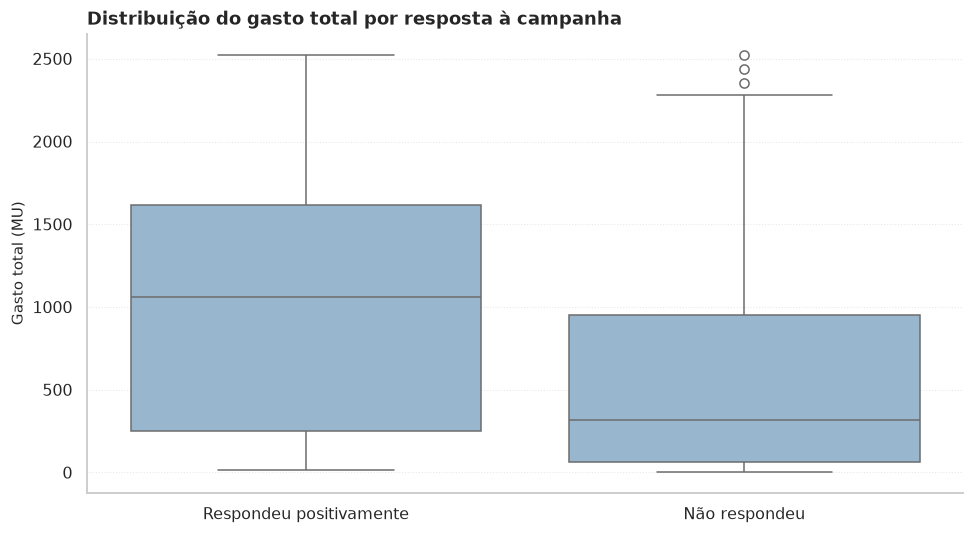

In [41]:
# Visualização 6 — Distribuição de TotalSpend por Response
boxplot_data = df[["TotalSpend", TARGET]].copy()
boxplot_data["ResponseLabel"] = boxplot_data[TARGET].map({
    0: "Não respondeu",
    1: "Respondeu positivamente"
})

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=boxplot_data,
    x="ResponseLabel",
    y="TotalSpend",
    ax=ax,
    color="#8FB8D8",
    showfliers=True
)

ax.set_title("Distribuição do gasto total por resposta à campanha", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Gasto total (MU)")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

Os clientes que responderam positivamente apresentam gasto médio de 987,39 MU e mediana de 1.057,50 MU. Entre os que não responderam, a média é de 538,24 MU e a mediana, 315,00 MU. A correlação de Spearman é 0,239, indicando associação positiva entre gasto total e resposta.

A diferença entre média e mediana nos grupos sugere distribuições assimétricas, o que justifica observar também a dispersão por meio do boxplot. O resultado não demonstra que o aumento de gastos provoque maior probabilidade de compra.

**Síntese da seção**

A renda apresenta associação expressiva com o volume de consumo. Os clientes que responderam positivamente também apresentam gastos superiores nas seis categorias e no agregado `TotalSpend`. O canal físico concentra a maior parte dos clientes, embora a taxa de resposta varie entre os canais predominantes. Já `NumDealsPurchases` apresenta comportamento não monotônico, com oscilações que precisam ser interpretadas considerando os tamanhos das amostras.

## 5. Histórico promocional e resposta às campanhas

Esta seção investiga a aceitação das cinco campanhas anteriores e sua relação com `Response`. São analisadas duas representações complementares: o total de campanhas aceitas por cliente e as flags individuais de aceitação.

A descrição do desafio identifica `AcceptedCmp1` a `AcceptedCmp5` como campanhas anteriores à campanha associada ao target. Essa ordem temporal sustenta sua investigação como histórico de relacionamento promocional, embora a disponibilidade efetiva de cada variável no instante da previsão deva ser respeitada na modelagem.

### 5.1 Construção e distribuição do histórico de aceitação

`PreviousCampaignsAccepted` é derivada pela soma das cinco flags de aceitação. A variável resume quantas campanhas anteriores foram aceitas por cada cliente, sem distinguir quais campanhas compõem essa contagem.

In [42]:
# Distribuição descritiva do número de campanhas anteriores aceitas
campaign_history = (
    df.groupby("PreviousCampaignsAccepted")
    .agg(Customers=("ID", "size"), CustomerShare=("ID", lambda x: len(x) / len(df) * 100))
    .sort_index()
)
display(campaign_history.style.format({"Customers": "{:,.0f}", "CustomerShare": "{:.2f}%"}))

,Customers,CustomerShare
PreviousCampaignsAccepted,,
0,"1,767",79.27%
1,324,14.54%
2,83,3.72%
3,44,1.97%
4,11,0.49%


A maior parte dos clientes não aceitou nenhuma campanha anterior (1.767; 79,27%). Outros 324 clientes (14,54%) aceitaram uma campanha, enquanto os grupos com duas, três ou quatro aceitações são progressivamente menores. O grupo com quatro aceitações contém apenas 11 clientes.

### 5.2 Histórico de aceitação por faixa de renda

A análise verifica se a presença e a quantidade média de aceitações anteriores variam entre as faixas de renda. `AcceptanceShare` representa a proporção de clientes de cada faixa que aceitou pelo menos uma campanha anterior.

In [43]:
# Histórico de aceitação por faixa de renda
history_income = (
    df.groupby("IncomeGroup", observed=True)
    .agg(
        Customers=("ID", "size"),
        MeanAcceptances=("PreviousCampaignsAccepted", "mean"),
        CustomersWithAcceptance=(
            "PreviousCampaignsAccepted",
            lambda x: (x > 0).sum()
        )
    )
)

history_income["AcceptanceShare"] = (
    history_income["CustomersWithAcceptance"]
    / history_income["Customers"]
    * 100
)

display(
    history_income.style.format({
        "Customers": "{:,.0f}",
        "MeanAcceptances": "{:.2f}",
        "CustomersWithAcceptance": "{:,.0f}",
        "AcceptanceShare": "{:.2f}%"
    })
)

,Customers,MeanAcceptances,CustomersWithAcceptance,AcceptanceShare
IncomeGroup,,,,
Low,553,0.08,44,7.96%
Medium-Low,550,0.14,71,12.91%
Medium-High,551,0.23,107,19.42%
High,551,0.74,236,42.83%


A participação de clientes que aceitaram pelo menos uma campanha anterior varia de 7,96% na faixa `Low` a 42,83% na faixa `High`. O resultado indica associação entre renda e histórico de aceitação, mas não permite atribuir uma relação causal entre essas características.

### 5.3 Histórico agregado × Response

A taxa de resposta é comparada segundo a quantidade de campanhas anteriores aceitas. Essa análise permite verificar se o histórico agregado diferencia grupos com comportamentos distintos diante da campanha piloto.

In [44]:
# Quantidade de campanhas anteriores aceitas × Response
campaign_history_response = analyze_response(df, "PreviousCampaignsAccepted", TARGET)

,Customers,PositiveResponses,ResponseRate
PreviousCampaignsAccepted,,,
0,"1,767",146,8.26%
1,324,101,31.17%
2,83,42,50.60%
3,44,35,79.55%
4,11,10,90.91%


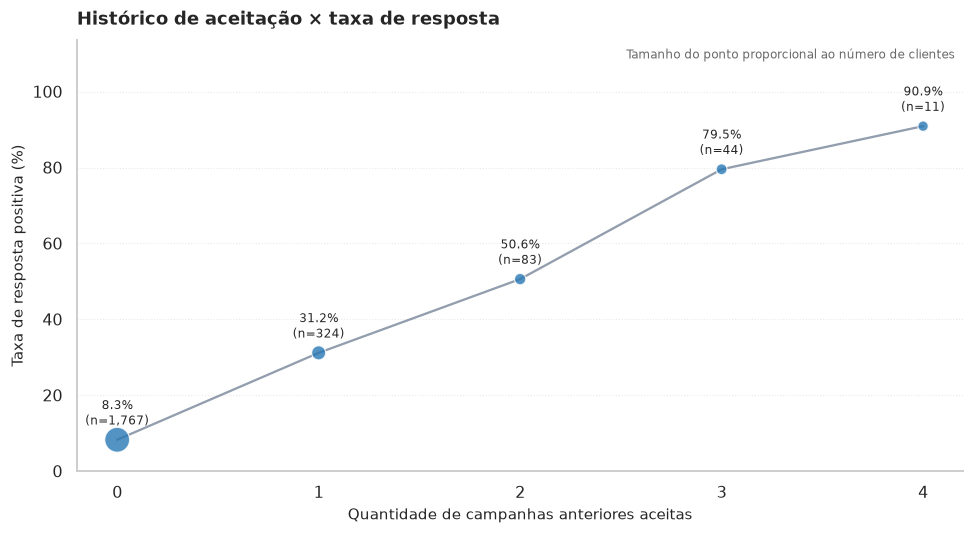

In [45]:
# Visualização 7 — Histórico agregado de aceitação × taxa de resposta
_campaign_history_plot = campaign_history_response.sort_index()

fig, ax = plt.subplots(figsize=(9, 5))

plot_rate_points(
    ax,
    _campaign_history_plot,
    title="Histórico de aceitação × taxa de resposta",
    xlabel="Quantidade de campanhas anteriores aceitas",
    connect=True,
    show_customers=True
)

plt.tight_layout()
plt.show()

A taxa de resposta aumenta conforme cresce a quantidade de campanhas anteriores aceitas: 8,26% para zero aceitações, 31,17% para uma, 50,60% para duas, 79,55% para três e 90,91% para quatro. A progressão é expressiva, mas os grupos com três e quatro aceitações contêm apenas 44 e 11 clientes, respectivamente.

### 5.4 Campanhas individuais × Response

A contagem agregada não identifica quais campanhas foram aceitas. Para complementar essa visão, as cinco flags são reorganizadas em formato longo e comparadas individualmente com `Response`.

Para cada campanha, são apresentados clientes que aceitaram e não aceitaram a oferta anterior, quantidade de respostas positivas e taxa de resposta da campanha piloto.

In [46]:
# Campanhas individuais × Response
campaign_response = (
    df[campaign_cols + [TARGET]]
    .melt(
        id_vars=TARGET,
        value_vars=campaign_cols,
        var_name="Campaign",
        value_name="Accepted"
    )
    .groupby(["Campaign", "Accepted"], observed=True)[TARGET]
    .agg(
        Customers="size",
        PositiveResponses="sum",
        ResponseRate="mean"
    )
    .reset_index()
)

campaign_response["AcceptanceStatus"] = campaign_response["Accepted"].map({
    0: "Não aceitou",
    1: "Aceitou"
})

campaign_response = campaign_response.drop(columns="Accepted")
campaign_response["ResponseRate"] *= 100

campaign_order = campaign_cols
campaign_response["Campaign"] = pd.Categorical(
    campaign_response["Campaign"],
    categories=campaign_order,
    ordered=True
)
campaign_response = campaign_response.sort_values(
    ["Campaign", "AcceptanceStatus"]
)

display(
    campaign_response.style.format({
        "Customers": "{:,.0f}",
        "PositiveResponses": "{:,.0f}",
        "ResponseRate": "{:.2f}%"
    })
)

,Campaign,Customers,PositiveResponses,ResponseRate,AcceptanceStatus
1,AcceptedCmp1,144,79,54.86%,Aceitou
0,AcceptedCmp1,"2,085",255,12.23%,Não aceitou
3,AcceptedCmp2,30,20,66.67%,Aceitou
2,AcceptedCmp2,"2,199",314,14.28%,Não aceitou
5,AcceptedCmp3,163,77,47.24%,Aceitou
4,AcceptedCmp3,"2,066",257,12.44%,Não aceitou
7,AcceptedCmp4,167,62,37.13%,Aceitou
6,AcceptedCmp4,"2,062",272,13.19%,Não aceitou
9,AcceptedCmp5,162,92,56.79%,Aceitou
8,AcceptedCmp5,"2,067",242,11.71%,Não aceitou


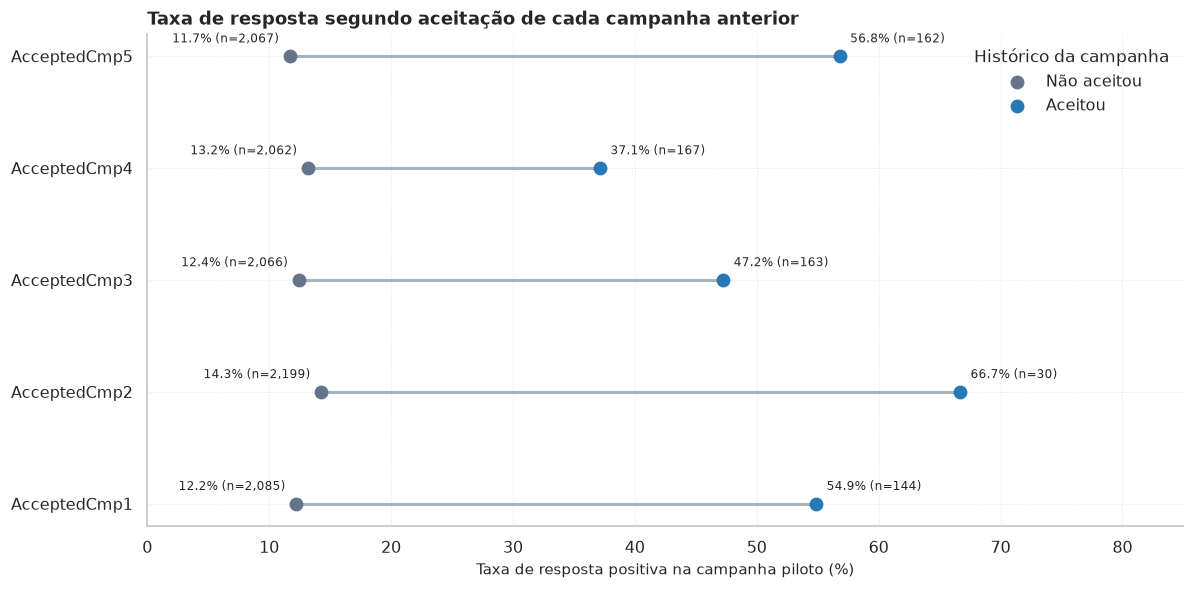

In [47]:
# Visualização 8 — Comparação individual das campanhas (dumbbell chart)
_campaign_rates = campaign_response.pivot(
    index="Campaign",
    columns="AcceptanceStatus",
    values="ResponseRate"
).reindex(campaign_order)

_campaign_counts = campaign_response.pivot(
    index="Campaign",
    columns="AcceptanceStatus",
    values="Customers"
).reindex(campaign_order)

fig, ax = plt.subplots(figsize=(11, 5.5))
y_positions = np.arange(len(campaign_order))

for i, campaign in enumerate(campaign_order):
    rate_no = _campaign_rates.loc[campaign, "Não aceitou"]
    rate_yes = _campaign_rates.loc[campaign, "Aceitou"]
    n_no = int(_campaign_counts.loc[campaign, "Não aceitou"])
    n_yes = int(_campaign_counts.loc[campaign, "Aceitou"])

    ax.hlines(i, rate_no, rate_yes, color="#A8B3C0", linewidth=2, zorder=1)
    ax.scatter(rate_no, i, s=65, color=COLOR_RESPONSE_0, label="Não aceitou" if i == 0 else None, zorder=2)
    ax.scatter(rate_yes, i, s=65, color=COLOR_RESPONSE_1, label="Aceitou" if i == 0 else None, zorder=2)

    ax.annotate(
        f"{rate_no:.1f}% (n={n_no:,})",
        (rate_no, i), xytext=(-7, 9), textcoords="offset points",
        ha="right", fontsize=8
    )
    ax.annotate(
        f"{rate_yes:.1f}% (n={n_yes:,})",
        (rate_yes, i), xytext=(7, 9), textcoords="offset points",
        ha="left", fontsize=8
    )

ax.set_yticks(y_positions)
ax.set_yticklabels(campaign_order)
ax.set_title("Taxa de resposta segundo aceitação de cada campanha anterior", loc="left")
ax.set_xlabel("Taxa de resposta positiva na campanha piloto (%)")
ax.set_ylabel("")
ax.legend(title="Histórico da campanha", frameon=False)
ax.set_xlim(0, 85)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

Em todas as cinco campanhas, a taxa de resposta positiva é superior entre os clientes que aceitaram anteriormente a respectiva oferta. A maior taxa observada no grupo que aceitou é de 66,67% em `AcceptedCmp2`, mas esse grupo contém somente 30 clientes. `AcceptedCmp5` apresenta 56,79% entre 162 clientes, com 92 respostas positivas.

Os grupos de aceitação se sobrepõem: um mesmo cliente pode ter aceitado mais de uma campanha. Portanto, as cinco comparações não representam amostras independentes. As diferenças são associações descritivas, não efeitos causais das campanhas.

### 5.5 Histórico de campanhas × frequência por canal

Esta análise verifica se a frequência média de compras nos canais Web, loja física e catálogo varia conforme o número de campanhas anteriores aceitas. Ela complementa a caracterização do histórico promocional com uma dimensão de comportamento de compra.

In [48]:
# Histórico de campanhas × frequência por canal
campaign_channel = (
    df.groupby("PreviousCampaignsAccepted")
    .agg(
        Customers=("ID", "size"),
        MeanWebPurchases=("NumWebPurchases", "mean"),
        MeanStorePurchases=("NumStorePurchases", "mean"),
        MeanCatalogPurchases=("NumCatalogPurchases", "mean")
    )
    .sort_index()
)

display(campaign_channel)

,Customers,MeanWebPurchases,MeanStorePurchases,MeanCatalogPurchases
PreviousCampaignsAccepted,,,,
0,1767,3.81,5.50,2.16
1,324,5.07,6.57,3.86
2,83,5.54,8.04,5.43
3,44,5.61,7.95,6.43
4,11,5.09,8.27,6.91


**Síntese da seção**

O histórico de campanhas apresenta associação forte com a resposta à campanha piloto, tanto na contagem agregada quanto nas cinco flags individuais. Os resultados tornam o histórico promocional uma dimensão relevante para investigação preditiva posterior. Antes da modelagem, será necessário preservar a definição temporal do desafio e evitar utilizar qualquer informação que não estivesse disponível no momento da previsão.

## 6. Engajamento digital e resposta

Esta seção investiga a relação entre visitas ao site e compras pela internet. Também avalia se grupos de frequência de visitas apresentam taxas diferentes de resposta à campanha piloto.

O número de visitas não deve ser interpretado automaticamente como intenção de compra ou conversão: visitas e compras são comportamentos distintos.

### 6.1 Visitas ao site × compras pela internet

A tabela apresenta, para cada quantidade de visitas no último mês, a quantidade de clientes e as médias e medianas de compras pela internet. A correlação de Spearman resume a associação monotônica entre as duas variáveis.

In [49]:
# Visitas ao site × compras pela internet
web_engagement = (
    df.groupby("NumWebVisitsMonth")
    .agg(
        Customers=("ID", "size"),
        MeanWebPurchases=("NumWebPurchases", "mean"),
        MedianWebPurchases=("NumWebPurchases", "median")
    )
    .sort_index()
)

display(web_engagement)

web_engagement_corr = df[
    ["NumWebVisitsMonth", "NumWebPurchases"]
].corr(method="spearman").iloc[0, 1]

print(f"Correlação de Spearman: {web_engagement_corr:.3f}")

,Customers,MeanWebPurchases,MedianWebPurchases
NumWebVisitsMonth,,,
0,7,4.86,2.00
1,149,3.71,3.00
2,202,4.22,4.00
3,205,4.51,5.00
4,217,4.51,5.00
5,280,4.33,4.00
6,339,4.27,3.00
7,393,3.64,3.00
8,342,3.89,3.00


Correlação de Spearman: -0.107


A correlação de Spearman entre visitas ao site e compras pela internet é -0,107, uma associação negativa fraca. A quantidade de visitas, portanto, não acompanha de forma monotônica a frequência de compras Web nesta base.

### 6.2 Segmentação do engajamento digital

`WebVisitsGroup` agrupa os clientes em quatro faixas de visitas mensais. A segmentação facilita a comparação das taxas de resposta e reduz o destaque dado a categorias muito raras da contagem original.

In [50]:
# Engajamento digital agrupado × Response (análise descritiva)
web_visits_response = analyze_response(df, "WebVisitsGroup", TARGET)

,Customers,PositiveResponses,ResponseRate
WebVisitsGroup,,,
0–2 visits,358,70,19.55%
3–5 visits,702,84,11.97%
6–8 visits,"1,074",150,13.97%
9+ visits,95,30,31.58%


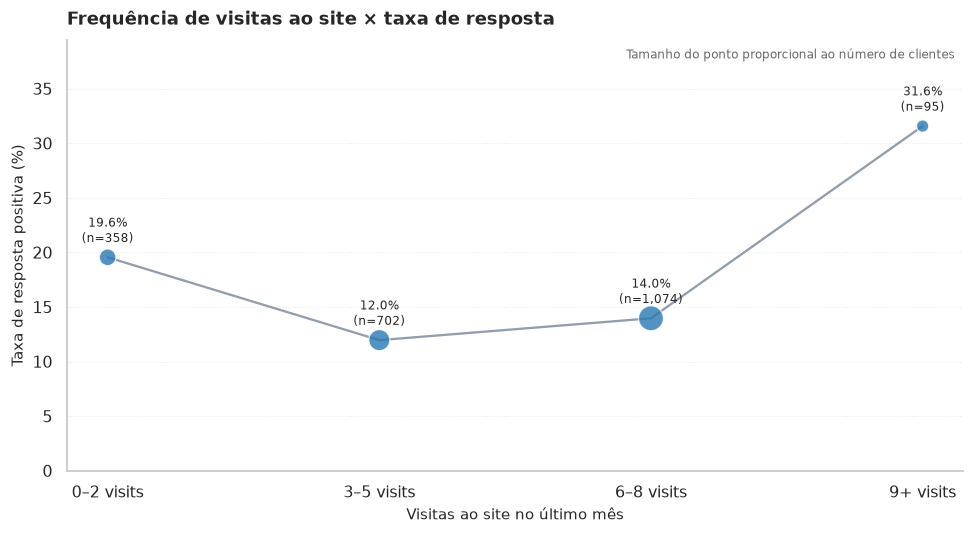

In [51]:
# Visualização 9 — Engajamento digital × taxa de resposta
fig, ax = plt.subplots(figsize=(9, 5))

plot_rate_points(
    ax,
    web_visits_response,
    title="Frequência de visitas ao site × taxa de resposta",
    xlabel="Visitas ao site no último mês",
    connect=True,
    show_customers=True
)

plt.tight_layout()
plt.show()

A taxa de resposta varia entre os grupos: 19,55% para 0–2 visitas, 11,97% para 3–5 visitas, 13,97% para 6–8 visitas e 31,58% para nove ou mais visitas. O padrão não é linear. O grupo de nove ou mais visitas contém 95 clientes, devendo ser interpretado com o tamanho da amostra em mente.

**Síntese da seção**

A correlação fraca entre visitas e compras Web indica que maior volume de navegação não representa necessariamente maior frequência de compra. Ao comparar `Response`, o grupo com nove ou mais visitas apresenta a maior taxa observada, mas a variação entre as faixas não é monotônica. O engajamento digital é uma dimensão complementar, não um substituto para o comportamento efetivo de compra.

## 7. Relacionamento e experiência do cliente

Esta seção investiga o tempo de relacionamento dos clientes, a recência da última compra e a frequência de compras. As três dimensões oferecem perspectivas complementares: duração do vínculo cadastral, atividade comercial recente e intensidade de compra.

`TenureDays` é criada no notebook 00 a partir da diferença entre a maior data de cadastro encontrada na base original e a data de cadastro de cada cliente. A coluna `Dt_Customer` é removida da base preparada após essa transformação. Portanto, `TenureDays` representa o tempo relativo desde o cadastro até uma referência interna ao conjunto de dados, e não necessariamente a duração do relacionamento na data efetiva da campanha ou na data atual.

### 7.1 Tempo de relacionamento × comportamento de compra

A agregação por `TenureGroup` reúne as medidas de tempo de relacionamento, gasto total, compras por canal e frequência total. As medidas de média e mediana de `TotalPurchases` são mantidas na mesma tabela para evitar duplicar a análise de frequência em uma tabela separada.

In [52]:
# Tempo de relacionamento × comportamento de compra
tenure_analysis = (
    df.groupby("TenureGroup", observed=True)
    .agg(
        Customers=("ID", "size"),
        MeanTenure=("TenureDays", "mean"),
        MeanTotalSpend=("TotalSpend", "mean"),
        MeanWebPurchases=("NumWebPurchases", "mean"),
        MeanStorePurchases=("NumStorePurchases", "mean"),
        MeanCatalogPurchases=("NumCatalogPurchases", "mean"),
        MeanPurchases=("TotalPurchases", "mean"),
        MedianPurchases=("TotalPurchases", "median")
    )
)

display(tenure_analysis)

,Customers,MeanTenure,MeanTotalSpend,MeanWebPurchases,MeanStorePurchases,MeanCatalogPurchases,MeanPurchases,MedianPurchases
TenureGroup,,,,,,,,
New,560,89.60,494.25,3.40,5.30,2.27,10.97,8.00
Short,558,269.36,547.73,3.88,5.76,2.53,12.17,11.00
Long,558,443.37,645.94,4.41,6.03,2.78,13.22,13.50
Very Long,553,616.07,735.81,4.72,6.17,2.97,13.85,14.00


Na base analisada, a média de compras aumenta de 10,97 no grupo `New` para 13,85 em `Very Long`. O gasto médio total também cresce entre esses grupos, de 494,25 MU para 735,81 MU. Os resultados indicam associação entre maior tempo de relacionamento e maior frequência e volume de consumo, sem estabelecer causalidade.

### 7.2 Recência × comportamento de compra

A tabela compara gastos e frequência por canal entre grupos definidos pelo número de dias desde a última compra. Média e mediana de `TotalSpend` são apresentadas para contextualizar a distribuição do consumo em cada faixa.

In [53]:
# Recência × comportamento de compra
recency_analysis = (
    df.groupby("RecencyGroup", observed=True)
    .agg(
        Customers=("ID", "size"),
        MeanTotalSpend=("TotalSpend", "mean"),
        MedianTotalSpend=("TotalSpend", "median"),
        MeanWebPurchases=("NumWebPurchases", "mean"),
        MeanStorePurchases=("NumStorePurchases", "mean"),
        MeanCatalogPurchases=("NumCatalogPurchases", "mean")
    )
)

display(recency_analysis)

,Customers,MeanTotalSpend,MedianTotalSpend,MeanWebPurchases,MeanStorePurchases,MeanCatalogPurchases
RecencyGroup,,,,,,
Up to 30 days,720,593.51,392.50,4.18,5.82,2.54
31-60 days,651,595.43,395.00,4.06,5.81,2.63
61-90 days,662,627.06,414.50,4.01,5.80,2.73
Over 90 days,196,610.68,404.00,4.23,5.83,2.69


Os gastos médios e as frequências por canal variam pouco entre as faixas de recência apresentadas. A tabela deve ser interpretada em conjunto com a comparação direta de `Response`, pois volume de consumo acumulado e proximidade da última compra são dimensões distintas.

### 7.3 Tempo de relacionamento e recência × Response

As taxas de resposta são comparadas para os grupos de tenure e recência. Os dois indicadores não são equivalentes: `TenureDays` descreve o tempo desde o cadastro, enquanto `Recency` representa os dias desde a última compra.

In [54]:
# Tempo de relacionamento × Response
tenure_response = analyze_response(df, "TenureGroup", TARGET)

,Customers,PositiveResponses,ResponseRate
TenureGroup,,,
New,560,48,8.57%
Short,558,54,9.68%
Long,558,87,15.59%
Very Long,553,145,26.22%


In [55]:
# Recência × Response
recency_response = analyze_response(df, "RecencyGroup", TARGET)

,Customers,PositiveResponses,ResponseRate
RecencyGroup,,,
Up to 30 days,720,173,24.03%
31-60 days,651,89,13.67%
61-90 days,662,61,9.21%
Over 90 days,196,11,5.61%


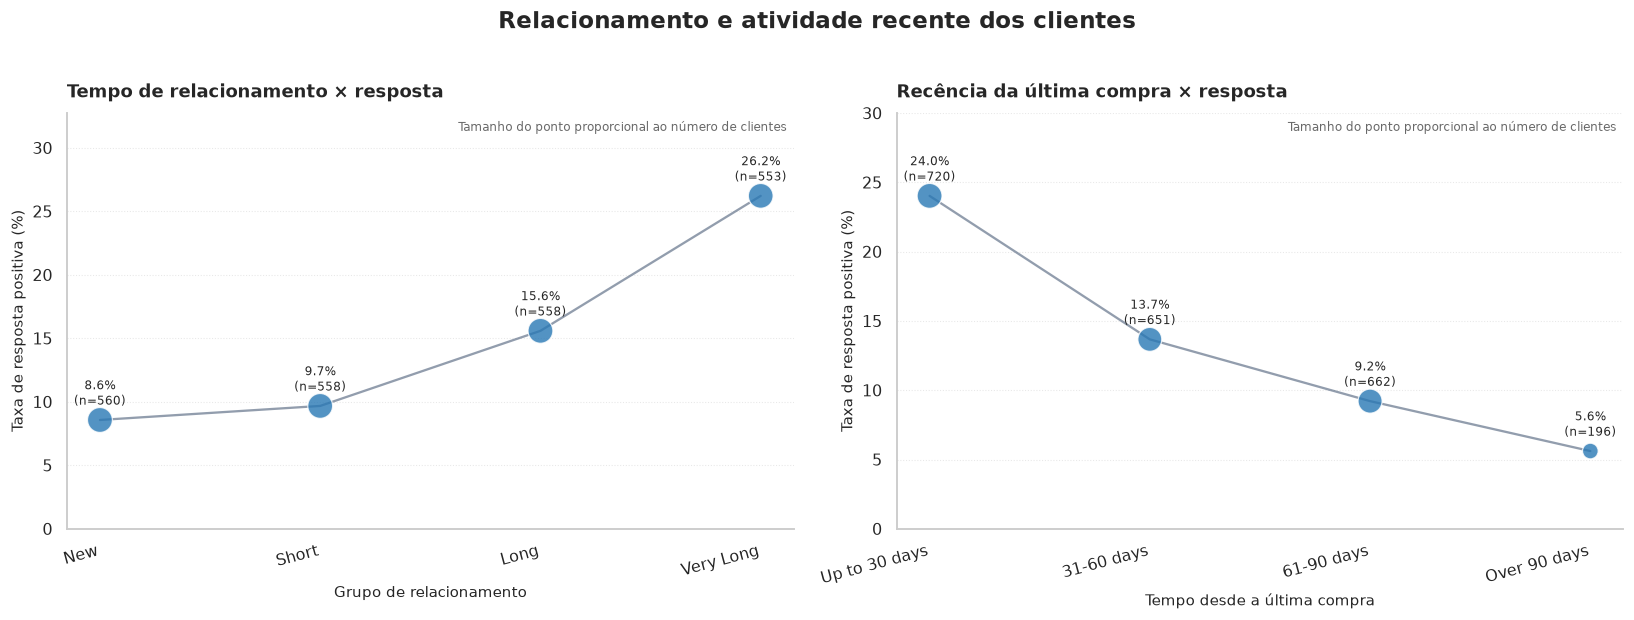

In [56]:
# Visualização 10 — Tenure e Recency × taxa de resposta
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

plot_rate_points(
    axes[0],
    tenure_response,
    title="Tempo de relacionamento × resposta",
    xlabel="Grupo de relacionamento",
    connect=True,
    show_customers=True,
    x_rotation=15
)

plot_rate_points(
    axes[1],
    recency_response,
    title="Recência da última compra × resposta",
    xlabel="Tempo desde a última compra",
    connect=True,
    show_customers=True,
    x_rotation=15
)

fig.suptitle(
    "Relacionamento e atividade recente dos clientes",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

A taxa de resposta cresce conforme aumenta o tempo de relacionamento: 8,57% em `New`, 9,68% em `Short`, 15,59% em `Long` e 26,22% em `Very Long`.

Para recência, o padrão é inverso: clientes cuja última compra ocorreu há até 30 dias apresentam taxa de 24,03%; a taxa diminui para 13,67% entre 31–60 dias, 9,21% entre 61–90 dias e 5,61% acima de 90 dias.

As duas dimensões apresentam associações distintas com a resposta: maior tempo de relacionamento está associado a taxas superiores, enquanto maior intervalo desde a última compra está associado a taxas inferiores.

**Síntese da seção**

Tempo de relacionamento e recência oferecem informações complementares sobre o vínculo do cliente com a empresa. Na amostra, clientes com maior tenure apresentam maior frequência média de compras e maior taxa de resposta; clientes com compras mais recentes também apresentam taxas de resposta superiores. A referência temporal utilizada em `TenureDays` é relativa à maior data de cadastro da base e não deve ser confundida com a data efetiva da campanha.

## 8. Exportação do Feature Data

Após a conclusão das análises exploratórias e da criação dos atributos derivados, o Feature Data é exportado em formato Parquet para utilização nas próximas etapas do projeto.

A exportação contempla explicitamente `ID`, `Response` e as 38 features definidas em `FEATURE_COLUMNS` (25 features base e 13 variáveis derivadas). Essa seleção preserva o contrato do artefato e evita incluir outras colunas que possam ser adicionadas temporariamente ao DataFrame durante a análise.

A variável `Response` é preservada como target e referência para análises posteriores, mas não deverá participar do processo de formação dos grupos de segmentação.

In [57]:
# Validação e exportação do Feature Data
BASE_FEATURES = [
    "Age", "Income", "Education", "Marital_Status", "Kidhome", "Teenhome", "Recency",
    "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts",
    "MntGoldProds", "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases",
    "NumStorePurchases", "NumWebVisitsMonth", "AcceptedCmp1", "AcceptedCmp2",
    "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Complain", "TenureDays"
]

FEATURE_COLUMNS = BASE_FEATURES + DERIVED_FEATURES

assert len(FEATURE_COLUMNS) == 38
assert len(set(FEATURE_COLUMNS)) == 38
assert set(["ID", "Response"] + FEATURE_COLUMNS).issubset(df.columns)
assert df["ID"].is_unique
assert df["Response"].isin([0, 1]).all()

feature_data = df[["ID", "Response"] + FEATURE_COLUMNS].copy()
feature_data.to_parquet(FEATURES_DATA, index=False)

print("FEATURES_DATA exportado com sucesso.")

FEATURES_DATA exportado com sucesso.


## 9. Conclusão

A análise exploratória permitiu caracterizar o perfil dos clientes, investigar seus padrões de consumo e relacionamento e identificar associações entre essas características e a resposta à campanha.

Como resultado desta etapa, foi construído e exportado o Feature Data, composto por 25 features base e 13 variáveis derivadas, totalizando 38 atributos. O artefato também preserva `ID` para identificação dos clientes e `Response` como target e referência analítica.

Os resultados são descritivos e não demonstram causalidade ou contribuição preditiva individual. As associações identificadas devem ser consideradas evidências exploratórias, não critérios definitivos para seleção de variáveis. A escolha dos atributos destinados aos experimentos de segmentação e propensão será conduzida na etapa específica de análise e seleção de features.